In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import qecnn
import support

import torch

from itertools import islice
from enhancer import EnhancerModel, WEIGHTS, choose_device, read_pairs, paired_paths

Using device: cpu


### Создание папки для хранения графиков

In [2]:
Path('figures').mkdir(exist_ok=True)

### Загрузка базовой модели

In [3]:
qecnn.device = choose_device()

baseline = qecnn.InferenceImageEnhancementModel(
    'best_model2026.pth'
)

### Вычисление PSNR базовой модели для каждого изображения по оригинальной

In [4]:
psnr_qecnn = []

for i, (comp, raw) in enumerate(
    islice(read_pairs(paired_paths('test')), 100)
):
    enhanced = support.GetEngancedRGB(baseline, comp, 480, 320)

    psnr = support.cal_psnr(
        raw / 255.0,
        enhanced / 255.0
    )

    psnr_qecnn.append(psnr)

    print(f'Image {i + 1}: {psnr:.3f} dB')

psnr_qecnn = np.array(psnr_qecnn)

print(f'Mean PSNR: {psnr_qecnn.mean():.3f} dB')

Image 1: 26.523 dB
Image 2: 26.117 dB
Image 3: 25.345 dB
Image 4: 27.005 dB
Image 5: 23.626 dB
Image 6: 29.963 dB
Image 7: 24.073 dB
Image 8: 21.208 dB
Image 9: 24.582 dB
Image 10: 25.655 dB
Image 11: 23.391 dB
Image 12: 23.332 dB
Image 13: 26.008 dB
Image 14: 26.282 dB
Image 15: 22.893 dB
Image 16: 21.675 dB
Image 17: 29.999 dB
Image 18: 29.272 dB
Image 19: 24.193 dB
Image 20: 23.991 dB
Image 21: 20.328 dB
Image 22: 22.101 dB
Image 23: 22.358 dB
Image 24: 23.440 dB
Image 25: 23.984 dB
Image 26: 25.005 dB
Image 27: 24.483 dB
Image 28: 25.984 dB
Image 29: 29.928 dB
Image 30: 18.807 dB
Image 31: 26.020 dB
Image 32: 19.233 dB
Image 33: 21.705 dB
Image 34: 22.947 dB
Image 35: 29.940 dB
Image 36: 24.044 dB
Image 37: 25.951 dB
Image 38: 25.491 dB
Image 39: 25.369 dB
Image 40: 27.012 dB
Image 41: 24.951 dB
Image 42: 23.533 dB
Image 43: 25.239 dB
Image 44: 24.976 dB
Image 45: 22.740 dB
Image 46: 30.770 dB
Image 47: 21.239 dB
Image 48: 22.259 dB
Image 49: 22.997 dB
Image 50: 28.658 dB
Image 51:

### Загрузка результатов моей модели

In [5]:
data = np.genfromtxt(
    'swinir_psnr.csv',
    delimiter=',',
    names=True
)

psnr_h265 = data['psnr_h265']
psnr_swinir = data['psnr_swinir']

indices = np.argsort(psnr_h265)

### Построение графика

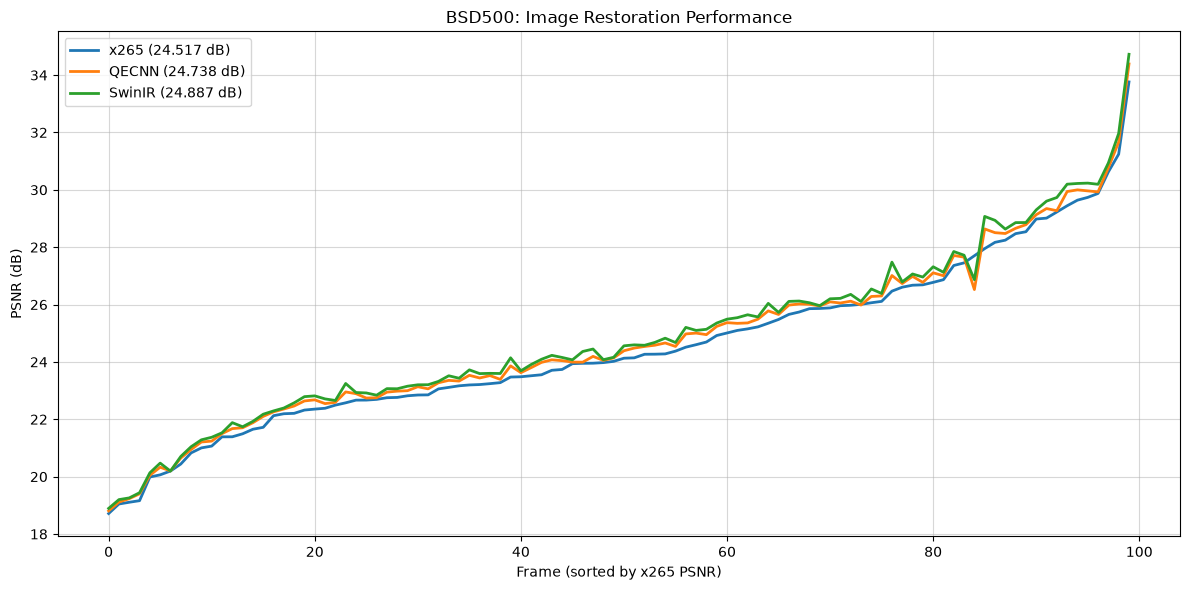

In [6]:
plt.figure(figsize=(12, 6))

plt.plot(
    psnr_h265[indices],
    label=f'x265 ({psnr_h265.mean():.3f} dB)',
    linewidth=2
)

plt.plot(
    psnr_qecnn[indices],
    label=f'QECNN ({psnr_qecnn.mean():.3f} dB)',
    linewidth=2
)

plt.plot(
    psnr_swinir[indices],
    label=f'SwinIR ({psnr_swinir.mean():.3f} dB)',
    linewidth=2
)

plt.xlabel('Frame (sorted by x265 PSNR)')
plt.ylabel('PSNR (dB)')
plt.title('BSD500: Image Restoration Performance')
plt.legend()
plt.grid(alpha=0.5)
plt.tight_layout()

plt.savefig('figures/psnr_comparison.png', dpi=300)
plt.show()

### Визуальное сравнение SwinIR и QECNN

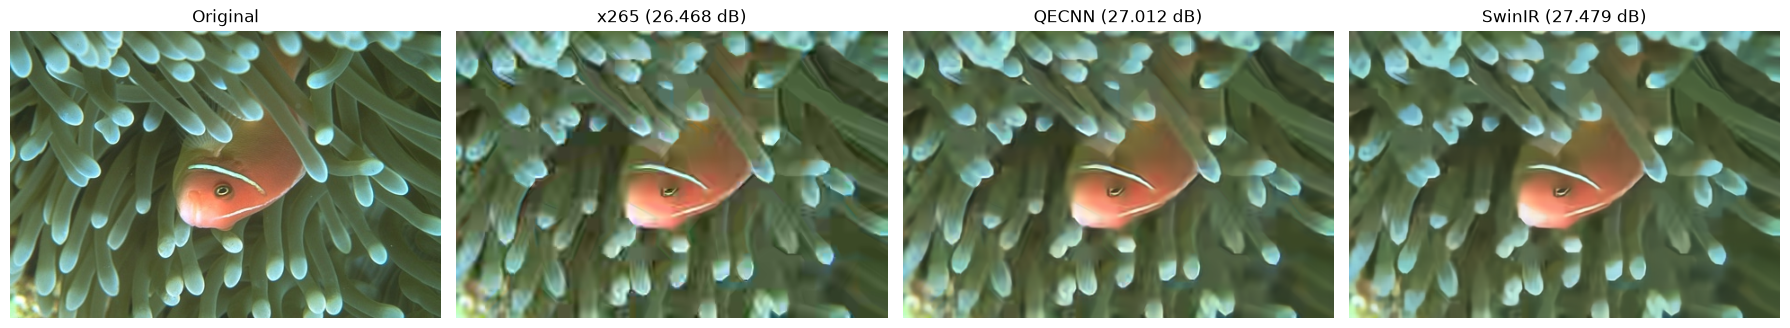

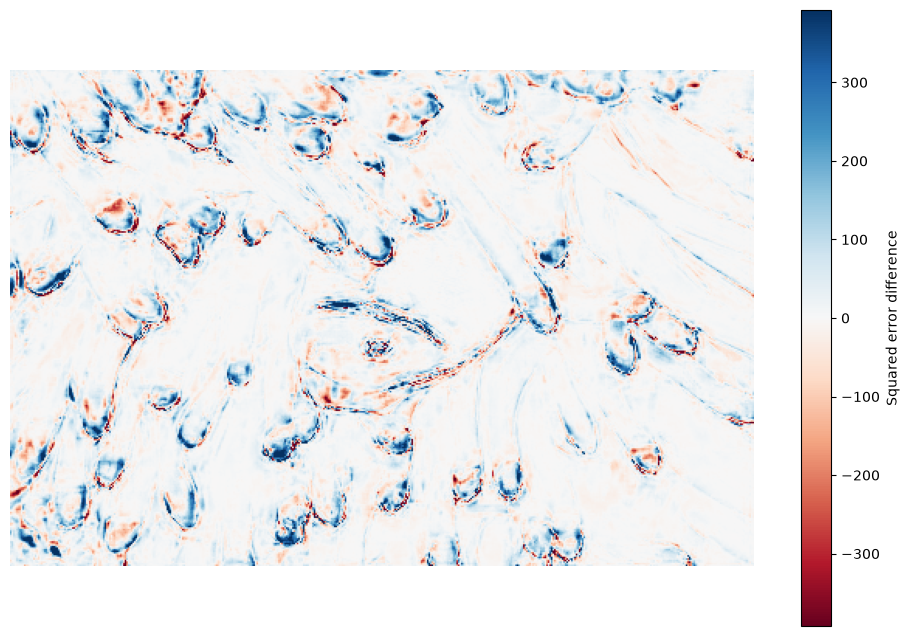

In [9]:
swinir = EnhancerModel().to(qecnn.device)
swinir.load_state_dict(torch.load(WEIGHTS, map_location=qecnn.device, weights_only=True))
swinir.eval()

i = np.argmax(psnr_swinir - psnr_qecnn)

comp, raw = list(islice(read_pairs(paired_paths('test')), 100))[i]

q = support.GetEngancedRGB(baseline, comp, 480, 320)
s = support.GetEngancedRGB(swinir, comp, 480, 320)

images = [raw, comp, q, s]
titles = [
    'Original',
    f'x265 ({psnr_h265[i]:.3f} dB)',
    f'QECNN ({psnr_qecnn[i]:.3f} dB)',
    f'SwinIR ({psnr_swinir[i]:.3f} dB)'
]

plt.figure(figsize=(18, 5))

for j in range(4):
    plt.subplot(1, 4, j + 1)
    plt.imshow(np.clip(images[j] / 255, 0, 1))
    plt.title(titles[j])
    plt.axis('off')

plt.tight_layout()
plt.savefig('figures/visual_comparison_QECNN_SwinIR.png', dpi=300)

diff = ((raw - q)**2 - (raw - s)**2).mean(axis=2)

vmax = np.percentile(np.abs(diff), 99)

plt.figure(figsize=(12, 8))
plt.imshow(diff, cmap='RdBu', vmin=-vmax, vmax=vmax)
plt.colorbar(label='Squared error difference')
plt.axis('off')

plt.savefig('figures/visual_improvement_QECNN_SwinIR.png', dpi=300)

plt.show()

### Визуальное сравнение SwinIR и x265

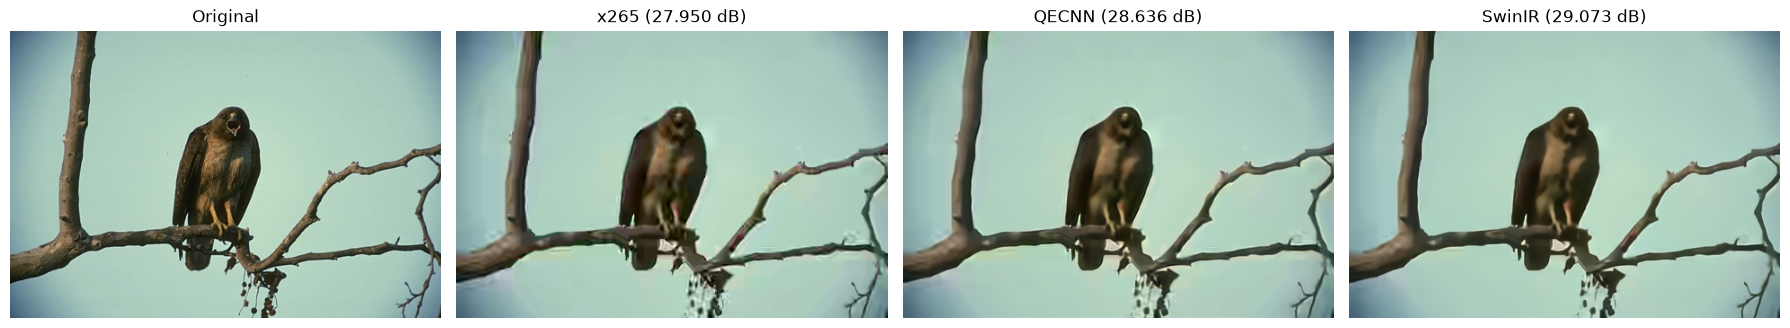

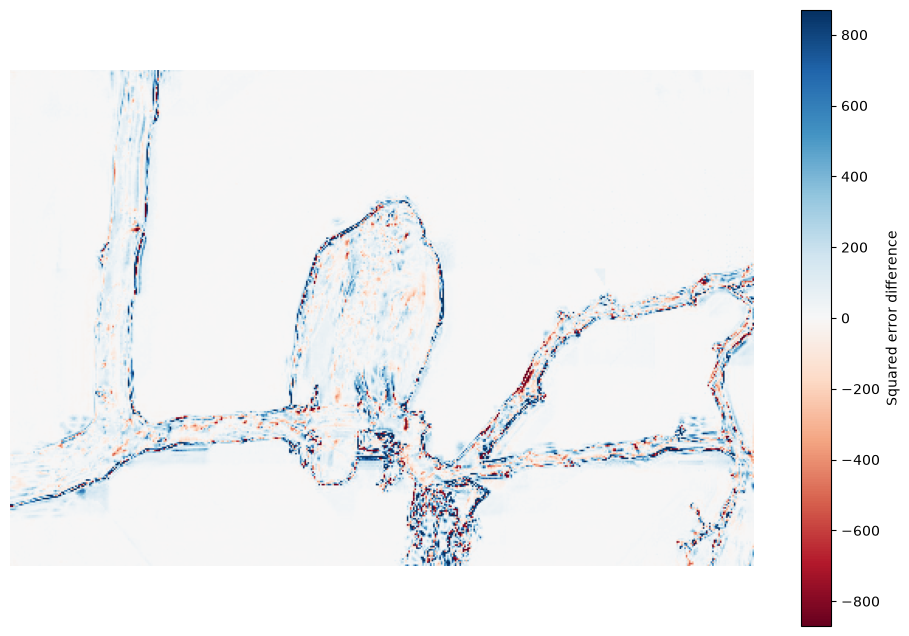

In [10]:
swinir = EnhancerModel().to(qecnn.device)
swinir.load_state_dict(torch.load(WEIGHTS, map_location=qecnn.device, weights_only=True))
swinir.eval()

i = np.argmax(psnr_swinir - psnr_h265)

comp, raw = list(islice(read_pairs(paired_paths('test')), 100))[i]

q = support.GetEngancedRGB(baseline, comp, 480, 320)
s = support.GetEngancedRGB(swinir, comp, 480, 320)

images = [raw, comp, q, s]
titles = [
    'Original',
    f'x265 ({psnr_h265[i]:.3f} dB)',
    f'QECNN ({psnr_qecnn[i]:.3f} dB)',
    f'SwinIR ({psnr_swinir[i]:.3f} dB)'
]

plt.figure(figsize=(18, 5))

for j in range(4):
    plt.subplot(1, 4, j + 1)
    plt.imshow(np.clip(images[j] / 255, 0, 1))
    plt.title(titles[j])
    plt.axis('off')

plt.tight_layout()
plt.savefig('figures/visual_comparison_base_SwinIR.png', dpi=300)

diff = ((raw - comp)**2 - (raw - s)**2).mean(axis=2)

vmax = np.percentile(np.abs(diff), 99)

plt.figure(figsize=(12, 8))
plt.imshow(diff, cmap='RdBu', vmin=-vmax, vmax=vmax)
plt.colorbar(label='Squared error difference')
plt.axis('off')

plt.savefig('figures/visual_improvement_base_SwinIR.png', dpi=300)

plt.show()